# La poule qui chante — Étude de marché à l'international
## Notebook 1 — Préparation, nettoyage et analyse exploratoire des données

**Contexte.** La poule qui chante (poulets Agriculture Biologique, activité 100 % France) souhaite s'étendre à l'international. Aucun pays ni continent n'est présélectionné. L'objectif est de construire un jeu de données pays permettant ensuite (notebook 2) de **regrouper les pays** (ACP + CAH + k-means) et d'identifier des cibles d'export.

**Contraintes du brief (Patrick, PDG)**
- partir des données FAO (*New Food Balances* 2017 + population) ;
- enrichir via une analyse **PESTEL** avec des données open data (Banque mondiale) — **au moins 8 variables** ;
- regrouper toutes les sources dans **un seul fichier** ;
- idéalement **≥ 100 pays couvrant ≥ 60 % de la population mondiale** ;
- créer **au moins 3 variables** par *feature engineering*.

**Sommaire**
1. Imports et configuration
2. Données FAO — disponibilité alimentaire 2017 (audit, nettoyage)
3. Données FAO — population 2000-2018
4. Feature engineering sur les données FAO
5. Enrichissement PESTEL — Banque mondiale (API)
6. Jointure des sources et table de correspondance pays
7. Valeurs manquantes
8. Valeurs aberrantes / atypiques et transformations
9. Analyse exploratoire
10. Contrôles de couverture et export du fichier final

## 1. Imports et configuration

In [1]:
import json
import time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import requests
import country_converter as coco  # pip install country_converter

pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 160)
sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams["figure.dpi"] = 110

DATA_DIR = Path("data")
CACHE_DIR = DATA_DIR / "cache_worldbank"
CACHE_DIR.mkdir(parents=True, exist_ok=True)

REF_YEAR = 2017          # FAO food balance year
POP_BASE_YEAR = 2007     # base year for 10-year population growth

## 2. Données FAO — disponibilité alimentaire 2017
### 2.1 Chargement et audit

In [2]:
food_raw = pd.read_csv(DATA_DIR / "DisponibiliteAlimentaire_2017.csv")
print(food_raw.shape)
food_raw.head()

(176600, 14)


,Code Domaine,Domaine,Code zone,Zone,Code Élément,Élément,Code Produit,Produit,Code année,Année,Unité,Valeur,Symbole,Description du Symbole
0,FBS,Nouveaux Bilans Alimentaire,2,Afghanistan,5511,Production,2511,Blé et produits,2017,2017,Milliers de tonnes,4281.0,S,Données standardisées
1,FBS,Nouveaux Bilans Alimentaire,2,Afghanistan,5611,Importations - Quantité,2511,Blé et produits,2017,2017,Milliers de tonnes,2302.0,S,Données standardisées
2,FBS,Nouveaux Bilans Alimentaire,2,Afghanistan,5072,Variation de stock,2511,Blé et produits,2017,2017,Milliers de tonnes,-119.0,S,Données standardisées
3,FBS,Nouveaux Bilans Alimentaire,2,Afghanistan,5911,Exportations - Quantité,2511,Blé et produits,2017,2017,Milliers de tonnes,0.0,S,Données standardisées
4,FBS,Nouveaux Bilans Alimentaire,2,Afghanistan,5301,Disponibilité intérieure,2511,Blé et produits,2017,2017,Milliers de tonnes,6701.0,S,Données standardisées


In [3]:
food_raw.info()

<class 'pandas.DataFrame'>
RangeIndex: 176600 entries, 0 to 176599
Data columns (total 14 columns):
 #   Column                  Non-Null Count   Dtype  
---  ------                  --------------   -----  
 0   Code Domaine            176600 non-null  str    
 1   Domaine                 176600 non-null  str    
 2   Code zone               176600 non-null  int64  
 3   Zone                    176600 non-null  str    
 4   Code Élément            176600 non-null  int64  
 5   Élément                 176600 non-null  str    
 6   Code Produit            176600 non-null  int64  
 7   Produit                 176600 non-null  str    
 8   Code année              176600 non-null  int64  
 9   Année                   176600 non-null  int64  
 10  Unité                   176600 non-null  str    
 11  Valeur                  176600 non-null  float64
 12  Symbole                 176600 non-null  str    
 13  Description du Symbole  176600 non-null  str    
dtypes: float64(1), int64(5), str(8)

In [4]:
audit = pd.DataFrame({
    "n_unique": food_raw.nunique(),
    "n_missing": food_raw.isna().sum(),
    "example": food_raw.iloc[0],
})
audit

,n_unique,n_missing,example
Code Domaine,1,0,FBS
Domaine,1,0,Nouveaux Bilans Alimentaire
Code zone,174,0,2
Zone,174,0,Afghanistan
Code Élément,17,0,5511
Élément,17,0,Production
Code Produit,98,0,2511
Produit,98,0,Blé et produits
Code année,1,0,2017
Année,1,0,2017


Constats :
- une seule année (2017), un seul domaine (FBS) : les colonnes `Code Domaine`, `Domaine`, `Code année`, `Année` sont constantes ;
- **174 zones**, 98 produits, 17 éléments ; aucune valeur manquante dans `Valeur` ;
- `Symbole` : *S* (données standardisées) ou *Fc* (valeur calculée) — pas de valeur estimée à exclure.

In [5]:
print("Full-row duplicates:", food_raw.duplicated().sum())
print("Duplicates on (zone, element, product):",
      food_raw.duplicated(["Code zone", "Code Élément", "Code Produit"]).sum())
food_raw[["Élément", "Unité"]].drop_duplicates().reset_index(drop=True)

Full-row duplicates: 0
Duplicates on (zone, element, product): 0


,Élément,Unité
0,Production,Milliers de tonnes
1,Importations - Quantité,Milliers de tonnes
2,Variation de stock,Milliers de tonnes
3,Exportations - Quantité,Milliers de tonnes
4,Disponibilité intérieure,Milliers de tonnes
5,Aliments pour animaux,Milliers de tonnes
6,Semences,Milliers de tonnes
7,Pertes,Milliers de tonnes
8,Résidus,Milliers de tonnes
9,Nourriture,Milliers de tonnes


Pas de doublon. Les unités sont homogènes par élément : quantités en **milliers de tonnes**, disponibilités par habitant en kg/an, kcal/jour ou g/jour.

**Risque de double comptage — Chine.** Dans les bilans FAO, la zone agrégée *Chine* (code 351) cumule Chine continentale, Hong Kong, Macao et Taïwan. On vérifie qu'elle n'est pas présente.

In [6]:
food_raw.loc[food_raw["Zone"].str.contains("Chine"), ["Code zone", "Zone"]].drop_duplicates()

,Code zone,Zone
32710,96,Chine - RAS de Hong-Kong
33871,128,Chine - RAS de Macao
34930,41,"Chine, continentale"
36103,214,"Chine, Taiwan Province de"


L'agrégat *Chine* (351) est absent : pas de double comptage. Les 4 entités sont conservées séparément.

### 2.2 Réduction aux colonnes utiles

In [7]:
food = (food_raw
        .rename(columns={"Code zone": "fao_code", "Zone": "zone", "Élément": "element",
                         "Produit": "product", "Valeur": "value"})
        [["fao_code", "zone", "element", "product", "value"]])
food.head()

,fao_code,zone,element,product,value
0,2,Afghanistan,Production,Blé et produits,4281.0
1,2,Afghanistan,Importations - Quantité,Blé et produits,2302.0
2,2,Afghanistan,Variation de stock,Blé et produits,-119.0
3,2,Afghanistan,Exportations - Quantité,Blé et produits,0.0
4,2,Afghanistan,Disponibilité intérieure,Blé et produits,6701.0


### 2.3 Focus volaille
Seul le produit **Viande de Volailles** décrit directement notre marché. On pivote ses éléments en colonnes (1 ligne = 1 pays).

In [8]:
poultry = (food[food["product"] == "Viande de Volailles"]
           .pivot_table(index=["fao_code", "zone"], columns="element", values="value", aggfunc="sum")
           .reset_index())
poultry.columns.name = None
print(poultry.shape)
poultry.isna().sum().sort_values(ascending=False)

(172, 19)


Aliments pour animaux                                            171
Semences                                                         171
Autres utilisations (non alimentaire)                            138
Traitement                                                       126
Pertes                                                           105
Alimentation pour touristes                                       94
Exportations - Quantité                                           37
Résidus                                                            8
Production                                                         4
Variation de stock                                                 3
Disponibilité intérieure                                           2
Importations - Quantité                                            2
Nourriture                                                         2
zone                                                               0
fao_code                          

In [9]:
poultry = poultry.rename(columns={
    "Production": "poultry_production_kt",
    "Importations - Quantité": "poultry_imports_kt",
    "Exportations - Quantité": "poultry_exports_kt",
    "Disponibilité intérieure": "poultry_domestic_supply_kt",
    "Disponibilité alimentaire en quantité (kg/personne/an)": "poultry_supply_kg_cap",
    "Disponibilité de protéines en quantité (g/personne/jour)": "poultry_protein_g_cap_day",
})
keep = ["fao_code", "zone", "poultry_production_kt", "poultry_imports_kt", "poultry_exports_kt",
        "poultry_domestic_supply_kt", "poultry_supply_kg_cap", "poultry_protein_g_cap_day"]
poultry = poultry[keep]
poultry[poultry.drop(columns=["poultry_exports_kt"]).isna().any(axis=1)]

,fao_code,zone,poultry_production_kt,poultry_imports_kt,poultry_exports_kt,poultry_domestic_supply_kt,poultry_supply_kg_cap,poultry_protein_g_cap_day
46,72,Djibouti,NaN,3.0,NaN,3.0,2.68,0.92
84,120,République démocratique populaire lao,NaN,NaN,NaN,NaN,10.91,3.59
93,132,Maldives,NaN,12.0,NaN,12.0,13.50,4.70
160,235,Ouzbékistan,NaN,NaN,NaN,NaN,1.96,0.63


Lecture des manquants :
- **Exportations** : ~37 pays sans ligne → dans les bilans FAO, une ligne absente signifie un flux nul ou négligeable. Imputation **0**.
- **Djibouti, Maldives** : pas de production déclarée (marchés 100 % importateurs) → production **0**.
- **Ouzbékistan, Laos** : ni importations, ni production, ni disponibilité intérieure → bilan incomplet, impossible de calculer la dépendance aux importations. **Exclus** (poids démographique faible : ~40 M hab.).

In [10]:
poultry["poultry_exports_kt"] = poultry["poultry_exports_kt"].fillna(0)
incomplete = poultry["poultry_domestic_supply_kt"].isna() & poultry["poultry_imports_kt"].isna()
print("Excluded (incomplete balance):", poultry.loc[incomplete, "zone"].tolist())
poultry = poultry[~incomplete].copy()
poultry["poultry_production_kt"] = poultry["poultry_production_kt"].fillna(0)
print(poultry.shape, "- remaining NA:", int(poultry.isna().sum().sum()))

Excluded (incomplete balance): ['République démocratique populaire lao', 'Ouzbékistan']
(170, 8) - remaining NA: 0


Contrôle de cohérence du bilan : *Disponibilité intérieure ≈ Production + Importations − Exportations ± Variation de stock*.

In [11]:
check = poultry["poultry_production_kt"] + poultry["poultry_imports_kt"] - poultry["poultry_exports_kt"]
gap = (poultry["poultry_domestic_supply_kt"] - check)
print(gap.describe().round(1))
poultry.assign(gap=gap).loc[gap.abs() > 20, ["zone", "poultry_domestic_supply_kt", "gap"]]

count    170.0
mean     -13.6
std       75.1
min     -859.0
25%       -7.0
50%        0.0
75%        0.0
max      120.0
dtype: float64


,zone,poultry_domestic_supply_kt,gap
7,Australie,1171.0,-72.0
12,Bolivie (État plurinational de),429.0,-104.0
25,Chili,672.0,-80.0
26,"Chine, continentale",18161.0,49.0
37,Bélarus,265.0,-67.0
39,Égypte,1250.0,23.0
43,Finlande,111.0,-22.0
44,France,1573.0,-182.0
50,Allemagne,1739.0,29.0
54,Grèce,178.0,-118.0


Pour la très grande majorité des pays l'écart est nul ou faible : il correspond aux **variations de stock**. Quelques écarts plus marqués (Japon, France) relèvent d'ajustements de la FAO (stocks, transformation). Ils n'affectent pas l'analyse : les ratios construits plus bas n'utilisent pas la disponibilité intérieure.

### 2.4 Indicateurs issus de l'ensemble des produits
Deux indicateurs de **transition alimentaire** sont construits à partir de tous les produits :
- la **part de la volaille dans la viande consommée** (kg/hab/an) ;
- la **part des protéines animales** dans l'apport protéique total (g/hab/jour).

In [12]:
MEATS = ["Viande de Bovins", "Viande d'Ovins/Caprins", "Viande de Suides",
         "Viande de Volailles", "Viande, Autre"]
ANIMAL_PRODUCTS = MEATS + [
    "Abats Comestible", "Beurre, Ghee", "Crème", "Graisses Animales Crue", "Oeufs",
    "Lait - Excl Beurre", "Poissons Eau Douce", "Perciform", "Poissons Pelagiques",
    "Poissons Marins, Autres", "Crustacés", "Cephalopodes", "Mollusques, Autres",
    "Animaux Aquatiques Autre", "Viande de Anim Aquatiq", "Huiles de Poissons",
    "Huiles de Foie de Poisso",
]
missing_items = set(ANIMAL_PRODUCTS) - set(food["product"])
assert not missing_items, missing_items

kg = food[food["element"] == "Disponibilité alimentaire en quantité (kg/personne/an)"]
meat_kg = (kg[kg["product"].isin(MEATS)].groupby("fao_code")["value"].sum()
           .rename("meat_supply_kg_cap"))

prot = food[food["element"] == "Disponibilité de protéines en quantité (g/personne/jour)"]
prot_total = prot.groupby("fao_code")["value"].sum().rename("protein_total_g_cap_day")
prot_animal = (prot[prot["product"].isin(ANIMAL_PRODUCTS)].groupby("fao_code")["value"].sum()
               .rename("protein_animal_g_cap_day"))

diet = pd.concat([meat_kg, prot_total, prot_animal], axis=1).reset_index()
diet.describe().round(1)

,fao_code,meat_supply_kg_cap,protein_total_g_cap_day,protein_animal_g_cap_day
count,172.0,172.0,172.0,172.0
mean,126.6,48.7,81.2,36.9
std,73.0,29.6,20.2,20.3
min,1.0,3.8,39.9,5.8
25%,66.8,21.2,64.2,20.2
50%,121.5,45.4,81.4,35.9
75%,188.2,71.5,96.4,52.0
max,276.0,137.1,141.3,101.1


Ordres de grandeur conformes aux références FAO (apport protéique moyen mondial ≈ 80 g/hab/jour, ~40 % d'origine animale).

## 3. Données FAO — population 2000-2018

In [13]:
pop_raw = pd.read_csv(DATA_DIR / "Population_2000_2018.csv")
print(pop_raw.shape)
print(pop_raw[["Élément", "Unité", "Produit"]].drop_duplicates())
print("Duplicates:", pop_raw.duplicated(["Code zone", "Année"]).sum(),
      "| missing values:", int(pop_raw["Valeur"].isna().sum()))

(4411, 15)
             Élément           Unité                 Produit
0  Population totale  1000 personnes  Population-Estimations
Duplicates: 0 | missing values: 0


In [14]:
pop = (pop_raw[pop_raw["Année"].isin([POP_BASE_YEAR, REF_YEAR])]
       .pivot_table(index="Code zone", columns="Année", values="Valeur")
       .mul(1000)  # thousands of people -> people
       .rename(columns={POP_BASE_YEAR: "population_2007", REF_YEAR: "population"})
       .reset_index().rename(columns={"Code zone": "fao_code"}))
pop.columns.name = None
print(pop.shape, "- NA:", pop.isna().sum().to_dict())
pop[pop["fao_code"].isin([68, 41, 231])]  # sanity check: France, China, USA

(237, 3) - NA: {'fao_code': 0, 'population_2007': 7, 'population': 1}


,fao_code,population_2007,population
35,41,1.345994e+09,1.421022e+09
58,68,6.186923e+07,6.484251e+07
207,231,3.006084e+08,3.250848e+08


Population France 2017 ≈ 64,8 M (métropole — les DOM sont des zones FAO distinctes), Chine ≈ 1,42 Md, États-Unis ≈ 325 M : cohérent avec UN WPP 2017.

La population contient davantage de zones (238) que les bilans (174) : les territoires sans bilan alimentaire disparaîtront à la jointure (sans incidence : pas de variable volaille).

## 4. Feature engineering (données FAO)
| Variable créée | Définition | Intérêt métier |
|---|---|---|
| `import_dependency_pct` | Importations / (Production + Importations) × 100 | Part du marché servie par l'étranger : ouverture du marché à un exportateur |
| `poultry_share_meat_pct` | kg volaille / kg viande totale × 100 | Place du poulet dans le régime carné |
| `animal_protein_share_pct` | protéines animales / protéines totales × 100 | Stade de transition alimentaire (pouvoir d'achat alimentaire) |
| `pop_growth_10y_pct` | (Pop 2017 / Pop 2007 − 1) × 100 | Dynamique de la demande |
| `poultry_food_market_kt` | kg/hab × population / 10⁶ | Taille du marché de consommation (contrôle) |

La dépendance aux importations est bornée entre 0 et 100 % grâce au dénominateur *Production + Importations* (le ratio Importations / Disponibilité intérieure dépasse 100 % pour les plateformes de réexport comme Hong Kong).

In [15]:
fao = (poultry.merge(diet, on="fao_code", how="left", validate="1:1")
              .merge(pop, on="fao_code", how="left", validate="1:1"))
print(fao.shape, "- NA:", int(fao.isna().sum().sum()))

resources = fao["poultry_production_kt"] + fao["poultry_imports_kt"]
fao["import_dependency_pct"] = np.where(resources > 0, fao["poultry_imports_kt"] / resources * 100, np.nan)
fao["poultry_share_meat_pct"] = fao["poultry_supply_kg_cap"] / fao["meat_supply_kg_cap"] * 100
fao["animal_protein_share_pct"] = fao["protein_animal_g_cap_day"] / fao["protein_total_g_cap_day"] * 100
fao["pop_growth_10y_pct"] = (fao["population"] / fao["population_2007"] - 1) * 100
fao["poultry_food_market_kt"] = fao["poultry_supply_kg_cap"] * fao["population"] / 1e6

fao[["import_dependency_pct", "poultry_share_meat_pct", "animal_protein_share_pct",
     "pop_growth_10y_pct", "poultry_food_market_kt"]].describe().round(1)

(170, 13) - NA: 1


,import_dependency_pct,poultry_share_meat_pct,animal_protein_share_pct,pop_growth_10y_pct,poultry_food_market_kt
count,170.0,170.0,170.0,169.0,170.0
mean,35.8,40.7,42.8,15.5,657.1
std,35.2,20.5,16.0,14.8,2136.8
min,0.0,1.7,8.9,-12.7,2.0
25%,4.0,23.5,29.2,4.8,28.4
50%,23.2,38.4,44.1,12.6,99.4
75%,69.7,55.9,56.9,25.0,365.0
max,100.0,86.7,73.3,75.6,18100.7


In [16]:
fao[fao[["import_dependency_pct", "poultry_share_meat_pct", "pop_growth_10y_pct"]].isna().any(axis=1)]

,fao_code,zone,poultry_production_kt,poultry_imports_kt,poultry_exports_kt,poultry_domestic_supply_kt,poultry_supply_kg_cap,poultry_protein_g_cap_day,meat_supply_kg_cap,protein_total_g_cap_day,protein_animal_g_cap_day,population_2007,population,import_dependency_pct,poultry_share_meat_pct,animal_protein_share_pct,pop_growth_10y_pct,poultry_food_market_kt
169,276,Soudan,67.0,2.0,0.0,69.0,1.6,0.54,21.38,67.88,21.14,NaN,40813397.0,2.898551,7.48363,31.143194,NaN,65.301435


## 5. Enrichissement PESTEL — Banque mondiale
### 5.1 Choix des variables

| Axe PESTEL | Question pour un exportateur de poulet bio | Variable | Source |
|---|---|---|---|
| **P**olitique | Le pays est-il stable ? | Stabilité politique & absence de violence (WGI, −2,5 à +2,5) | Banque mondiale — WGI |
| **E**conomique | Les consommateurs peuvent-ils payer un produit premium ? | PIB/hab en parité de pouvoir d'achat ($ intl constants 2021) | Banque mondiale — WDI |
| **E**conomique | Le marché est-il ouvert aux importations ? | Importations volaille, dépendance aux importations | FAO |
| **S**ocial | Mode de vie / distribution moderne ? | Taux d'urbanisation (%) | Banque mondiale — WDI |
| **S**ocial | Démographie, habitudes alimentaires | Population, croissance, kg volaille/hab, part volaille, protéines animales | FAO |
| **T**echnologique | Peut-on acheminer un produit frais sous chaîne du froid ? | Logistics Performance Index (1-5), édition 2018 | Banque mondiale — LPI |
| **E**nvironnemental | Coût carbone / logistique du transport | Distance orthodromique Paris – capitale (km) | Coordonnées Banque mondiale, calcul |
| **L**égal | Le cadre réglementaire facilite-t-il les échanges ? | Qualité de la réglementation (WGI, −2,5 à +2,5) | Banque mondiale — WGI |

La **distance** est aussi une variable de *feature engineering* (calculée à partir des coordonnées des capitales).

Remarque : le LPI n'existe pas pour 2017 (éditions 2016 et 2018) ; on retient 2018, la plus proche et la plus complète.

In [17]:
WB_BASE = "https://api.worldbank.org/v2"

def fetch_wb(indicator: str, year: int, source: int | None = None) -> pd.DataFrame:
    # Download one World Bank indicator for all countries (cached as JSON).
    cache = CACHE_DIR / f"{indicator}_{year}.json"
    if cache.exists():
        rows = json.loads(cache.read_text())
    else:
        params = {"date": year, "format": "json", "per_page": 1000}
        if source:
            params["source"] = source
        r = requests.get(f"{WB_BASE}/country/all/indicator/{indicator}", params=params, timeout=60)
        r.raise_for_status()
        rows = r.json()[1]
        cache.write_text(json.dumps(rows))
    df = pd.DataFrame({
        "iso3": [x["countryiso3code"] for x in rows],
        "wb_name": [x["country"]["value"] for x in rows],
        "value": [x["value"] for x in rows],
    })
    return df

WB_INDICATORS = {
    # column name: (indicator code, year, source id)
    "gdp_cap_ppp": ("NY.GDP.PCAP.PP.KD", REF_YEAR, None),
    "urban_pct": ("SP.URB.TOTL.IN.ZS", REF_YEAR, None),
    "political_stability": ("GOV_WGI_PV.EST", REF_YEAR, 3),
    "regulatory_quality": ("GOV_WGI_RQ.EST", REF_YEAR, 3),
    "lpi_score": ("LP.LPI.OVRL.XQ", 2018, None),
}

wb_frames = {}
for col, (ind, year, src) in WB_INDICATORS.items():
    df = fetch_wb(ind, year, src)
    wb_frames[col] = df
    print(f"{col:20s} {ind:20s} rows={len(df):4d}  non-null={df['value'].notna().sum():4d}  "
          f"no ISO3={int((df['iso3'] == '').sum())}")

gdp_cap_ppp          NY.GDP.PCAP.PP.KD    rows= 265  non-null= 246  no ISO3=5


urban_pct            SP.URB.TOTL.IN.ZS    rows= 265  non-null= 264  no ISO3=5
political_stability  GOV_WGI_PV.EST       rows= 216  non-null= 212  no ISO3=9
regulatory_quality   GOV_WGI_RQ.EST       rows= 216  non-null= 212  no ISO3=9
lpi_score            LP.LPI.OVRL.XQ       rows= 265  non-null= 206  no ISO3=5


Les indicateurs WGI renvoient quelques territoires sans code ISO3 (Anguilla, Réunion, Martinique…) ; ils n'ont pas d'équivalent dans le périmètre retenu et sont écartés. Les agrégats régionaux (« Euro area », « World »…) sont éliminés via la liste officielle des pays.

In [18]:
cache = CACHE_DIR / "countries_meta.json"
if cache.exists():
    meta_rows = json.loads(cache.read_text())
else:
    r = requests.get(f"{WB_BASE}/country", params={"format": "json", "per_page": 400}, timeout=60)
    r.raise_for_status()
    meta_rows = r.json()[1]
    cache.write_text(json.dumps(meta_rows))

countries = pd.DataFrame({
    "iso3": [x["id"] for x in meta_rows],
    "wb_region": [x["region"]["value"].strip() for x in meta_rows],
    "income_group": [x["incomeLevel"]["value"].strip() for x in meta_rows],
    "capital": [x["capitalCity"] for x in meta_rows],
    "lat": pd.to_numeric([x["latitude"] for x in meta_rows], errors="coerce"),
    "lon": pd.to_numeric([x["longitude"] for x in meta_rows], errors="coerce"),
})
countries = countries[countries["wb_region"] != "Aggregates"].reset_index(drop=True)
print(countries.shape)

wb = countries.copy()
for col, df in wb_frames.items():
    s = df[df["iso3"] != ""].drop_duplicates("iso3").set_index("iso3")["value"].rename(col)
    wb = wb.merge(s, left_on="iso3", right_index=True, how="left")
wb.describe().round(2)

(217, 6)


,lat,lon,gdp_cap_ppp,urban_pct,political_stability,regulatory_quality,lpi_score
count,211.00,211.00,199.00,217.00,205.00,205.00,159.00
mean,18.89,19.14,25525.81,60.99,-0.04,0.02,2.86
std,24.21,70.39,25804.64,23.76,0.97,0.96,0.57
min,-41.29,-175.22,1020.85,13.52,-2.73,-2.10,1.95
25%,4.39,-14.44,5935.75,41.71,-0.67,-0.68,2.43
50%,17.30,19.26,16128.58,62.78,0.03,-0.08,2.70
75%,39.88,50.21,36756.91,80.40,0.81,0.70,3.21
max,64.18,179.09,133322.63,100.00,1.75,2.19,4.20


### 5.2 Feature engineering : distance à Paris
Distance orthodromique (formule de haversine) entre Paris et la capitale de chaque pays.

In [19]:
PARIS = (48.8566, 2.3522)

def haversine_km(lat1, lon1, lat2, lon2):
    lat1, lon1, lat2, lon2 = map(np.radians, [lat1, lon1, lat2, lon2])
    a = np.sin((lat2 - lat1) / 2) ** 2 + np.cos(lat1) * np.cos(lat2) * np.sin((lon2 - lon1) / 2) ** 2
    return 2 * 6371 * np.arcsin(np.sqrt(a))

wb["distance_paris_km"] = haversine_km(PARIS[0], PARIS[1], wb["lat"], wb["lon"])
wb.loc[wb["iso3"].isin(["DEU", "USA", "CHN", "ZAF", "BRA"]), ["iso3", "capital", "distance_paris_km"]].round(0)

,iso3,capital,distance_paris_km
26,BRA,Brasilia,8726.0
36,CHN,Beijing,8198.0
50,DEU,Berlin,878.0
203,USA,Washington D.C.,6166.0
214,ZAF,Pretoria,8684.0


Paris–Berlin ≈ 880 km, Paris–Washington ≈ 6 200 km, Paris–Pékin ≈ 8 200 km : cohérent.

## 6. Jointure des sources
La FAO utilise ses propres codes pays ; la Banque mondiale utilise l'ISO3. Correspondance via `country_converter` (classification *FAOcode*), complétée manuellement pour 2 codes non reconnus.

In [20]:
fao["iso3"] = coco.convert(fao["fao_code"].tolist(), src="FAOcode", to="ISO3", not_found=None)
MANUAL_ISO3 = {41: "CHN", 276: "SDN"}   # China mainland, Sudan (post-2011)
fao["iso3"] = fao.apply(lambda r: MANUAL_ISO3.get(r["fao_code"], r["iso3"]), axis=1)
fao["iso3"] = fao["iso3"].where(fao["iso3"].astype(str).str.len() == 3)
print("Unmapped:", fao.loc[fao["iso3"].isna(), "zone"].tolist())
print("Duplicate ISO3:", fao["iso3"].duplicated().sum())

41 not found in FAOcode


276 not found in FAOcode


Unmapped: []
Duplicate ISO3: 0


In [21]:
df = fao.merge(wb, on="iso3", how="left", validate="1:1", indicator=True)
print(df["_merge"].value_counts())
print("FAO zones not in the World Bank list:", df.loc[df["_merge"] == "left_only", "zone"].tolist())
df = df.drop(columns="_merge")

_merge
both          169
left_only       1
right_only      0
Name: count, dtype: int64
FAO zones not in the World Bank list: ['Chine, Taiwan Province de']


**Taïwan** n'est pas couvert par la Banque mondiale (statut politique). Il restera avec des manquants et sera traité à l'étape suivante.

## 7. Valeurs manquantes

In [22]:
FEATURES_RAW = [
    "poultry_supply_kg_cap", "poultry_imports_kt", "import_dependency_pct", "poultry_share_meat_pct",
    "animal_protein_share_pct", "population", "pop_growth_10y_pct", "gdp_cap_ppp", "urban_pct",
    "political_stability", "regulatory_quality", "lpi_score", "distance_paris_km",
]
na = df[FEATURES_RAW].isna().sum().to_frame("n_missing")
na["pct"] = (na["n_missing"] / len(df) * 100).round(1)
na.sort_values("n_missing", ascending=False)

,n_missing,pct
lpi_score,27,15.9
gdp_cap_ppp,7,4.1
political_stability,3,1.8
regulatory_quality,3,1.8
pop_growth_10y_pct,1,0.6
distance_paris_km,1,0.6
urban_pct,1,0.6
animal_protein_share_pct,0,0.0
poultry_imports_kt,0,0.0
poultry_supply_kg_cap,0,0.0


In [23]:
df["n_missing"] = df[FEATURES_RAW].isna().sum(axis=1)
df.loc[df["n_missing"] > 0, ["zone", "population", "n_missing"] +
       [c for c in FEATURES_RAW if df[c].isna().any()]].sort_values("n_missing", ascending=False)

,zone,population,n_missing,pop_growth_10y_pct,gdp_cap_ppp,urban_pct,political_stability,regulatory_quality,lpi_score,distance_paris_km
144,"Chine, Taiwan Province de",23674546.0,6,3.259580,NaN,NaN,NaN,NaN,NaN,NaN
105,Nouvelle-Calédonie,277150.0,4,13.898352,NaN,66.968339,NaN,NaN,NaN,16742.928132
45,Polynésie française,276102.0,4,5.093236,NaN,61.789694,NaN,NaN,NaN,15711.807707
80,République populaire démocratique de Corée,25429825.0,2,5.132615,NaN,61.820608,-0.354386,-2.103745,NaN,8770.910834
21,Cabo Verde,537498.0,1,13.143182,8234.560003,69.199999,0.720325,-0.139147,NaN,4448.180762
15,Belize,375769.0,1,25.664744,11572.300793,43.421109,0.027457,-0.539547,NaN,8652.836960
5,Antigua-et-Barbuda,95426.0,1,13.567229,27199.195240,24.850026,0.614623,0.218442,NaN,6705.874260
32,Azerbaïdjan,9845320.0,1,12.850135,19659.004856,56.433189,-0.455635,-0.185370,NaN,3812.446079
30,Cuba,11339254.0,1,0.783317,NaN,76.960327,0.572967,-1.140077,2.20,7718.930600
53,Kiribati,114158.0,1,18.265356,2822.020923,52.973470,0.951951,-0.677652,NaN,14362.197440


**Stratégie**
1. Pays avec **plus d'une variable manquante** → exclus (données trop lacunaires pour les positionner de manière fiable ; il s'agit surtout de micro-États insulaires et de Taïwan).
2. Pays avec **une seule** variable manquante (quasi exclusivement le LPI) → imputation par la **médiane du groupe *région × niveau de revenu*** Banque mondiale (repli sur la médiane du niveau de revenu). Le LPI étant fortement lié au revenu, c'est plus fidèle qu'une médiane globale.

In [24]:
excluded = df.loc[df["n_missing"] > 1, ["zone", "population"]]
print(f"Excluded: {len(excluded)} countries, {excluded['population'].sum() / 1e6:.0f} M people")
print(excluded["zone"].tolist())
df = df[df["n_missing"] <= 1].copy()

imputed_log = []
for col in FEATURES_RAW:
    mask = df[col].isna()
    if not mask.any():
        continue
    med_ri = df.groupby(["wb_region", "income_group"])[col].transform("median")
    med_i = df.groupby("income_group")[col].transform("median")
    fill = med_ri.fillna(med_i)
    for z in df.loc[mask, "zone"]:
        imputed_log.append((z, col))
    df.loc[mask, col] = fill[mask]

print(f"{len(imputed_log)} imputed values:", imputed_log)
assert df[FEATURES_RAW].isna().sum().sum() == 0
df = df.drop(columns="n_missing")

Excluded: 4 countries, 50 M people
['Polynésie française', 'République populaire démocratique de Corée', 'Nouvelle-Calédonie', 'Chine, Taiwan Province de']
27 imputed values: [('Soudan', 'pop_growth_10y_pct'), ('Cuba', 'gdp_cap_ppp'), ('Venezuela (République bolivarienne du)', 'gdp_cap_ppp'), ('Yémen', 'gdp_cap_ppp'), ('Antigua-et-Barbuda', 'lpi_score'), ('Barbade', 'lpi_score'), ('Botswana', 'lpi_score'), ('Belize', 'lpi_score'), ('Cabo Verde', 'lpi_score'), ('Azerbaïdjan', 'lpi_score'), ('Dominique', 'lpi_score'), ('Kiribati', 'lpi_score'), ('Grenade', 'lpi_score'), ('Chine - RAS de Macao', 'lpi_score'), ('Mozambique', 'lpi_score'), ('Namibie', 'lpi_score'), ('Vanuatu', 'lpi_score'), ('Nicaragua', 'lpi_score'), ('Timor-Leste', 'lpi_score'), ('Saint-Kitts-et-Nevis', 'lpi_score'), ('Sainte-Lucie', 'lpi_score'), ('Saint-Vincent-et-les Grenadines', 'lpi_score'), ('Suriname', 'lpi_score'), ('Eswatini', 'lpi_score'), ('République-Unie de Tanzanie', 'lpi_score'), ('Éthiopie', 'lpi_score'), 

## 8. Valeurs atypiques et transformations
### 8.1 Détection
Méthode de l'écart interquartile (IQR, 1,5 × IQR) sur chaque variable.

In [25]:
def iqr_outliers(s: pd.Series) -> pd.Series:
    q1, q3 = s.quantile([0.25, 0.75])
    iqr = q3 - q1
    return (s < q1 - 1.5 * iqr) | (s > q3 + 1.5 * iqr)

out_count = pd.Series({c: iqr_outliers(df[c]).sum() for c in FEATURES_RAW}, name="n_outliers")
out_count.sort_values(ascending=False).to_frame()

,n_outliers
poultry_imports_kt,19
population,18
gdp_cap_ppp,5
poultry_supply_kg_cap,3
pop_growth_10y_pct,2
distance_paris_km,1
lpi_score,1
political_stability,1
import_dependency_pct,0
animal_protein_share_pct,0


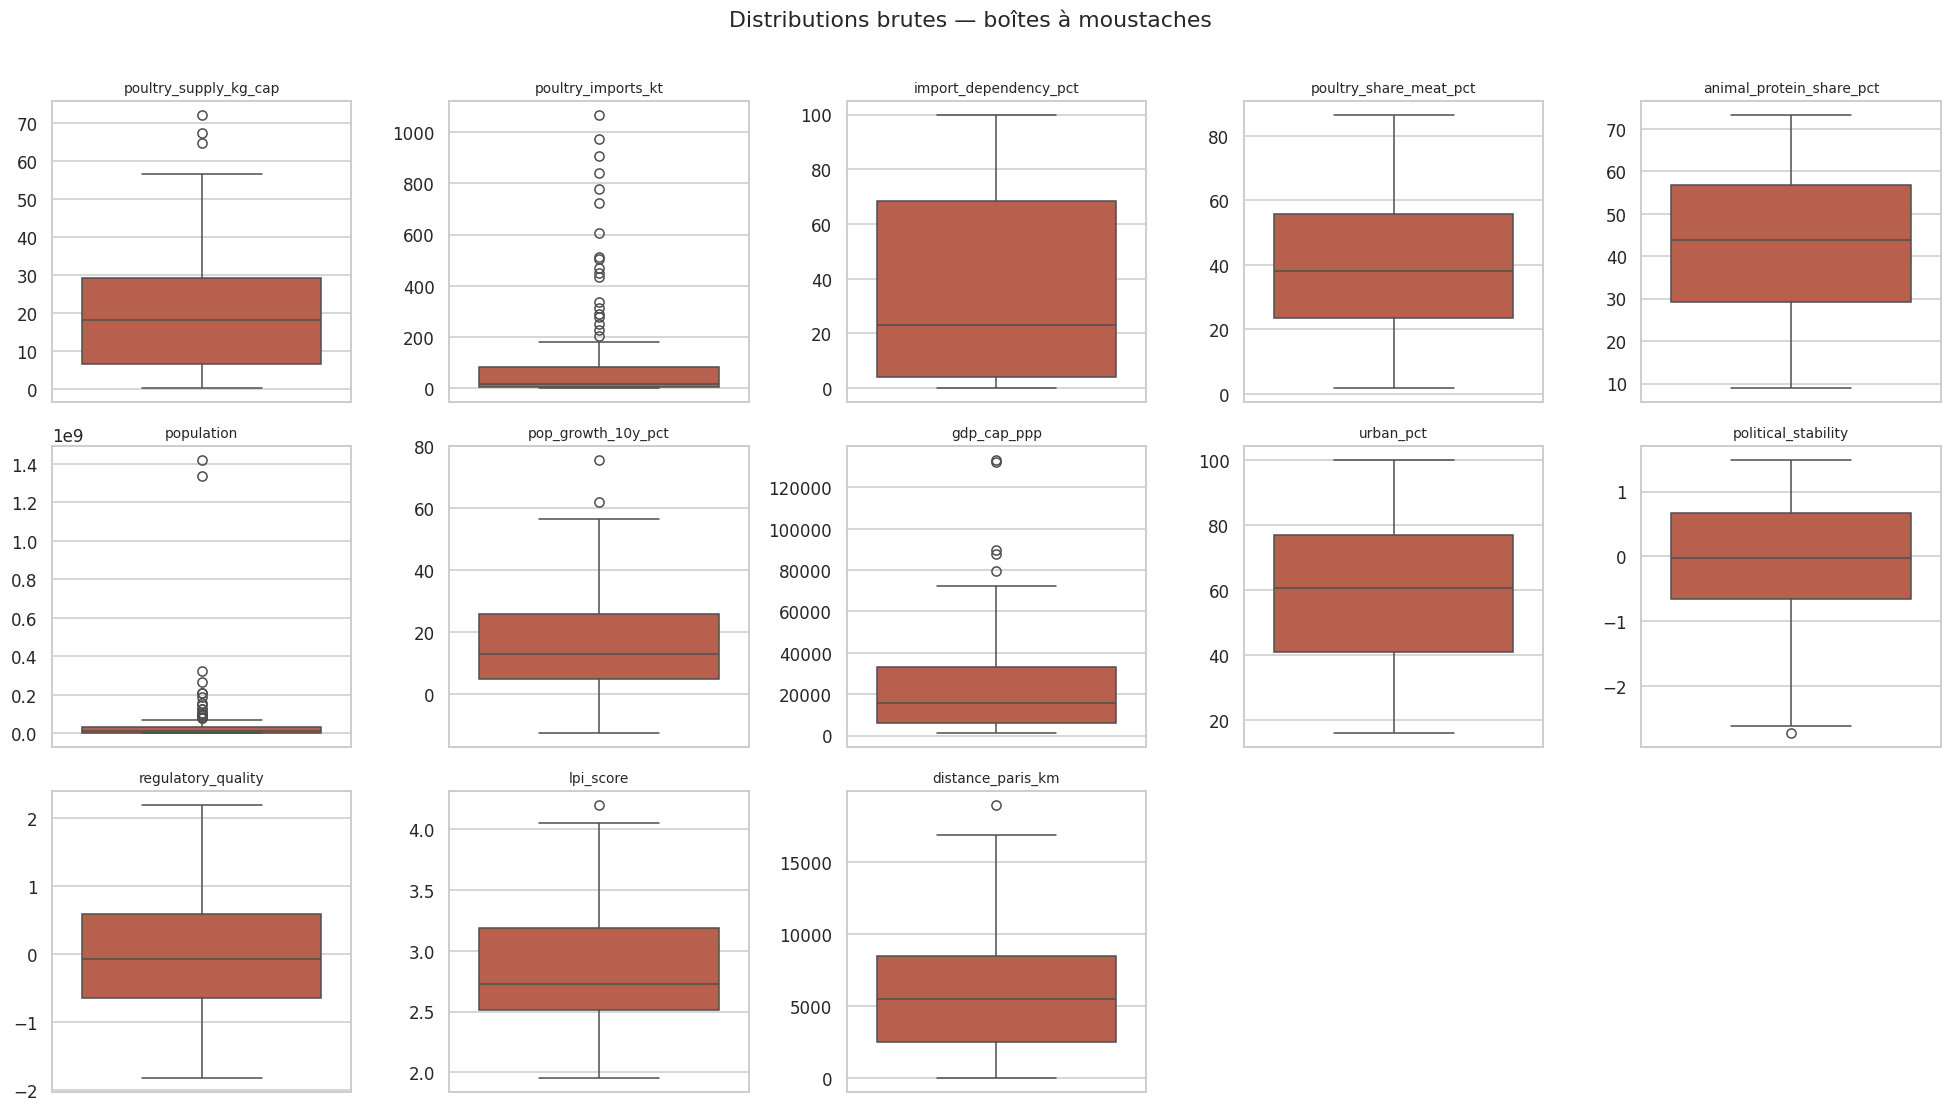

In [26]:
fig, axes = plt.subplots(3, 5, figsize=(18, 10))
for ax, col in zip(axes.flat, FEATURES_RAW):
    sns.boxplot(y=df[col], ax=ax, color="#C8553D")
    ax.set_title(col, fontsize=9)
    ax.set_ylabel("")
for ax in axes.flat[len(FEATURES_RAW):]:
    ax.axis("off")
plt.suptitle("Distributions brutes — boîtes à moustaches", y=1.01)
plt.tight_layout()
plt.show()

In [27]:
for col in ["poultry_imports_kt", "population", "gdp_cap_ppp", "poultry_supply_kg_cap"]:
    top = df.loc[iqr_outliers(df[col])].nlargest(6, col)[["zone", col]]
    print(f"\n{col}:\n", top.to_string(index=False))


poultry_imports_kt:
                                                zone  poultry_imports_kt
                                              Japon              1069.0
                                            Mexique               972.0
                           Chine - RAS de Hong-Kong               907.0
                                          Allemagne               842.0
Royaume-Uni de Grande-Bretagne et d'Irlande du Nord               779.0
                                    Arabie saoudite               722.0

population:
                  zone   population
  Chine, continentale 1421021791.0
                 Inde 1338676785.0
États-Unis d'Amérique  325084756.0
            Indonésie  264650963.0
             Pakistan  207906209.0
               Brésil  207833823.0

gdp_cap_ppp:
                 zone   gdp_cap_ppp
Chine - RAS de Macao 133322.632678
          Luxembourg 132169.829576
             Norvège  89664.908642
             Irlande  87731.789705
              Suisse  793

**Interprétation** : les valeurs extrêmes sont **réelles**, pas des erreurs de saisie (Chine et Inde pour la population, Japon / Mexique / Chine pour les importations, Samoa / Saint-Vincent / Israël pour la consommation par habitant, Qatar / Luxembourg pour le PIB/hab). Elles portent de l'information métier : **on les conserve**.

En revanche, les variables d'échelle (population, importations, PIB/hab, distance) ont des distributions très asymétriques : sans transformation, quelques pays écraseraient l'ACP et le clustering (méthodes basées sur la variance / distance euclidienne). On applique une transformation **log**.

In [28]:
skew_before = df[FEATURES_RAW].skew()

LOG_VARS = {"population": "log_population", "poultry_imports_kt": "log_poultry_imports",
            "gdp_cap_ppp": "log_gdp_cap_ppp"}
for raw, logc in LOG_VARS.items():
    df[logc] = np.log10(df[raw] + (1 if raw == "poultry_imports_kt" else 0))  # +1: some imports are 0

skew_after = pd.Series({raw: df[logc].skew() for raw, logc in LOG_VARS.items()})
pd.DataFrame({"skew_raw": skew_before[list(LOG_VARS)], "skew_log10": skew_after}).round(2)

,skew_raw,skew_log10
population,7.84,-0.30
poultry_imports_kt,3.28,0.16
gdp_cap_ppp,1.87,-0.26


La transformation log ramène l'asymétrie de ces trois variables sous |skew| < 0,5.

La **distance** n'est pas transformée : son asymétrie brute est modérée (0,75) et un log exagérerait artificiellement les écarts entre voisins proches de Paris (la France, à distance ≈ 0, deviendrait un point extrême).

## 9. Analyse exploratoire

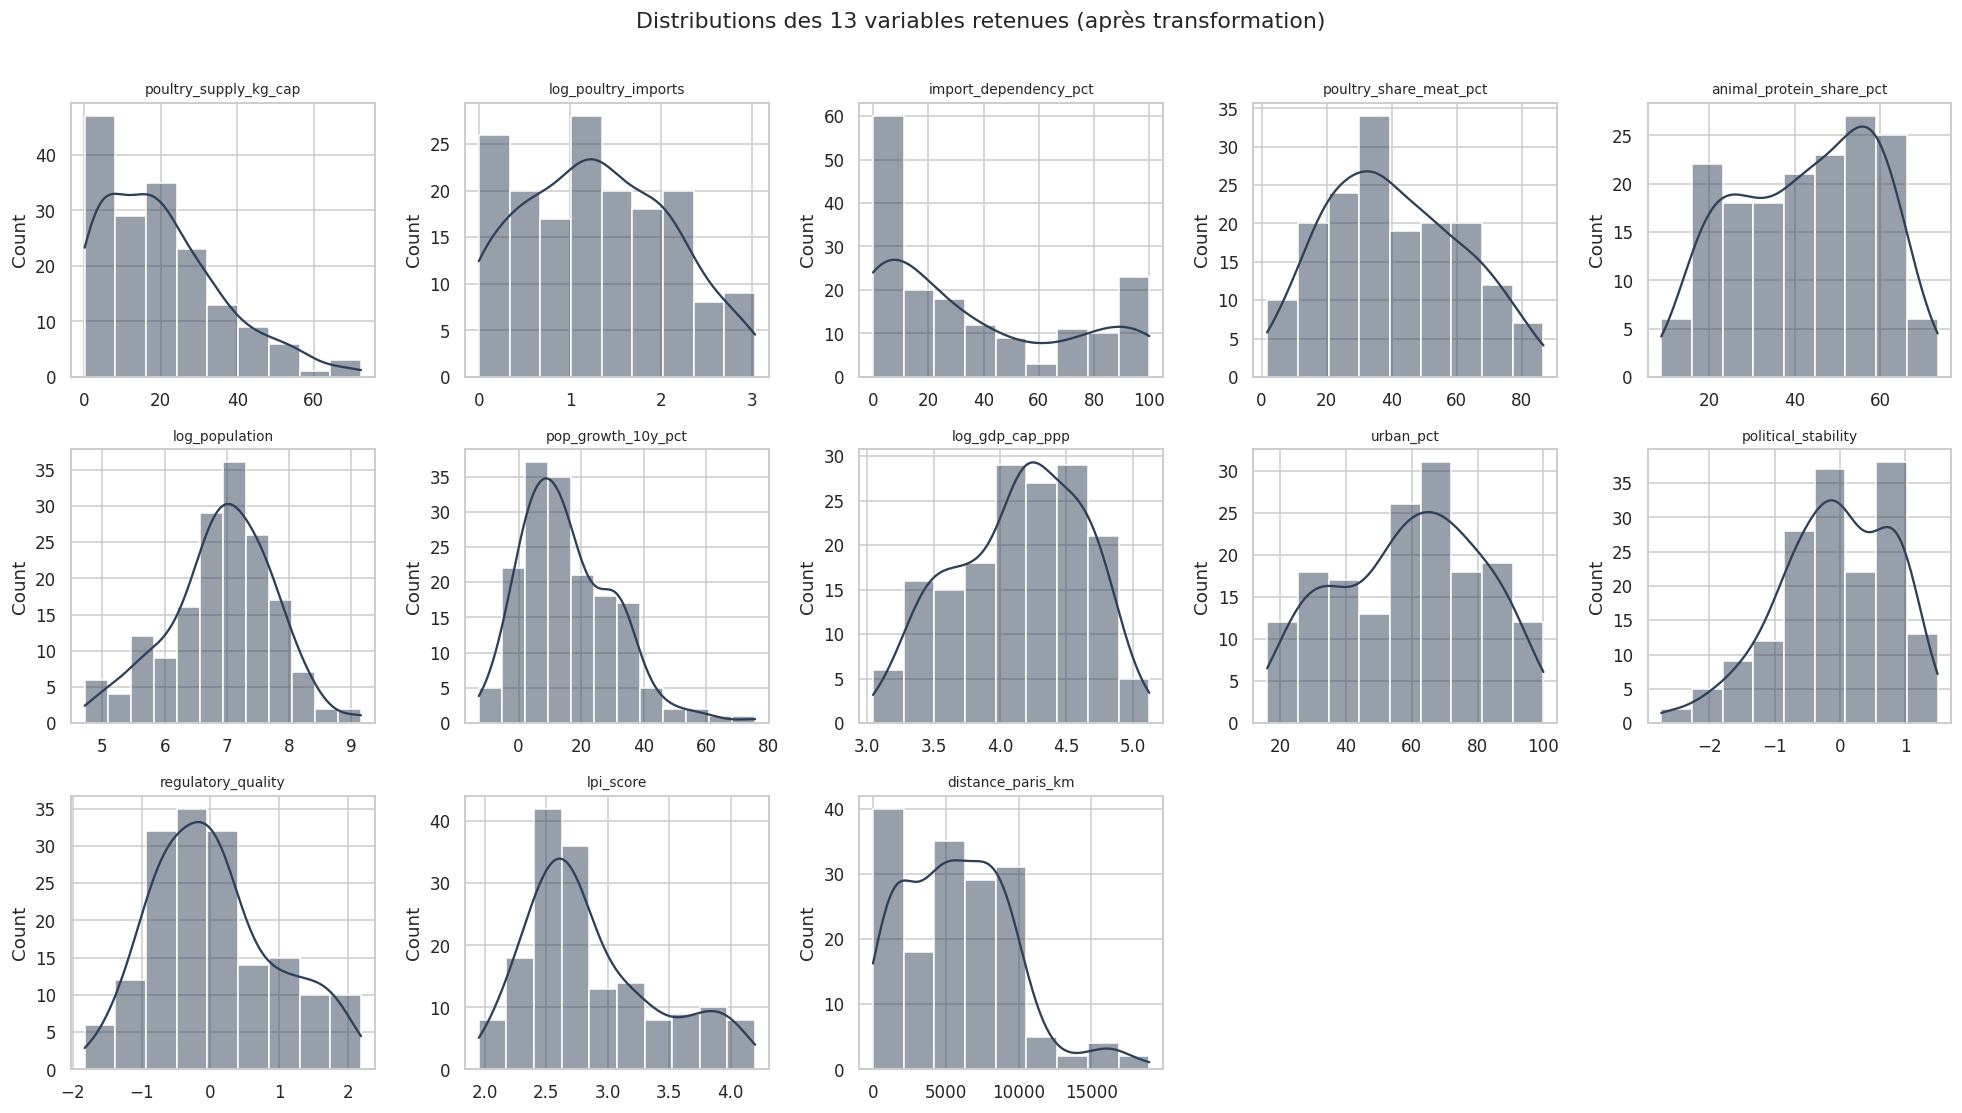

In [29]:
FEATURES = [
    "poultry_supply_kg_cap", "log_poultry_imports", "import_dependency_pct", "poultry_share_meat_pct",
    "animal_protein_share_pct", "log_population", "pop_growth_10y_pct", "log_gdp_cap_ppp", "urban_pct",
    "political_stability", "regulatory_quality", "lpi_score", "distance_paris_km",
]
fig, axes = plt.subplots(3, 5, figsize=(18, 10))
for ax, col in zip(axes.flat, FEATURES):
    sns.histplot(df[col], kde=True, ax=ax, color="#2E4057")
    ax.set_title(col, fontsize=9)
    ax.set_xlabel("")
for ax in axes.flat[len(FEATURES):]:
    ax.axis("off")
plt.suptitle("Distributions des 13 variables retenues (après transformation)", y=1.01)
plt.tight_layout()
plt.show()

### 9.1 Corrélations

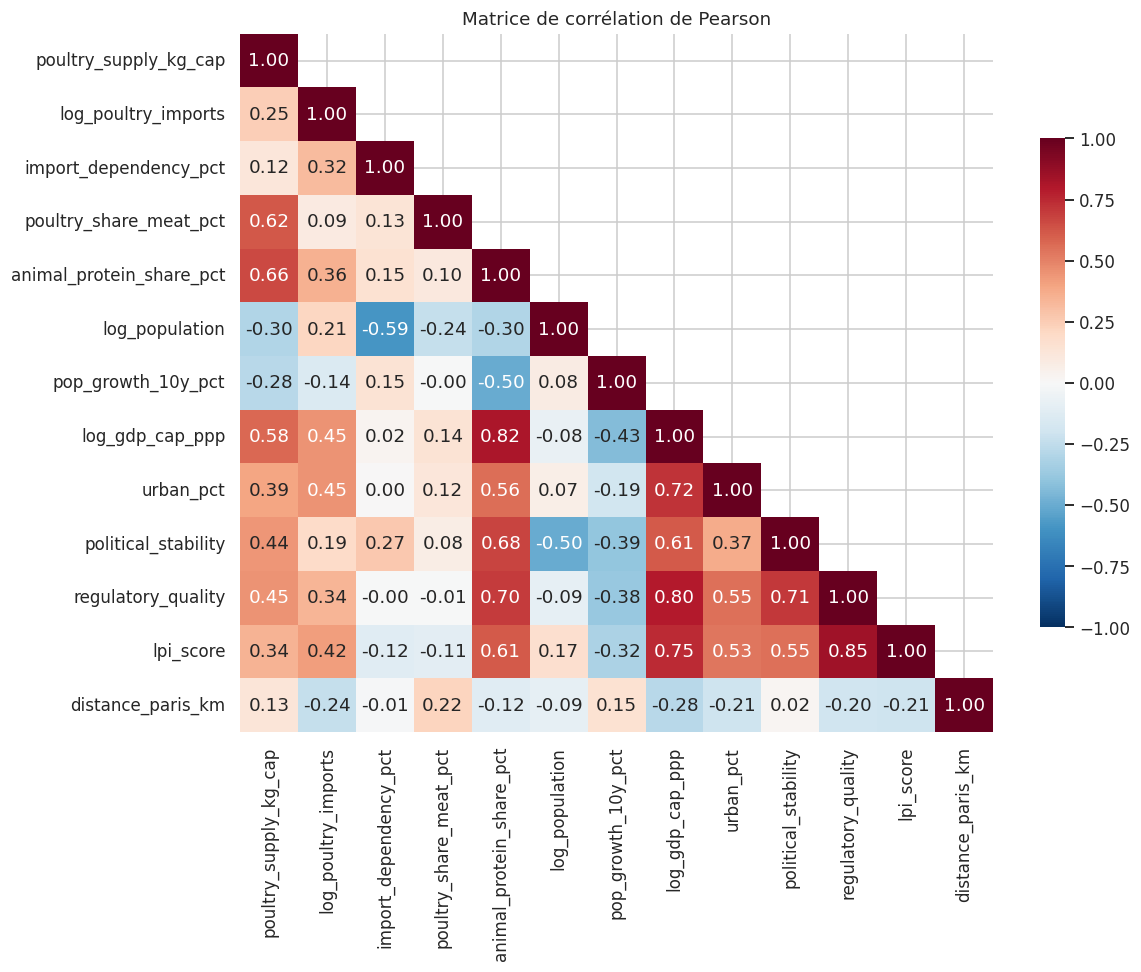

In [30]:
corr = df[FEATURES].corr()
plt.figure(figsize=(11, 9))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="RdBu_r", center=0, vmin=-1, vmax=1,
            mask=np.triu(np.ones_like(corr, dtype=bool), 1), cbar_kws={"shrink": .7})
plt.title("Matrice de corrélation de Pearson")
plt.tight_layout()
plt.show()

In [31]:
pairs = (corr.where(np.triu(np.ones_like(corr, dtype=bool), 1)).stack()
         .rename("r").reset_index().assign(abs_r=lambda d: d["r"].abs())
         .sort_values("abs_r", ascending=False))
pairs.head(10).round(2)

,level_0,level_1,r,abs_r
141,regulatory_quality,lpi_score,0.85,0.85
59,animal_protein_share_pct,log_gdp_cap_ppp,0.82,0.82
101,log_gdp_cap_ppp,regulatory_quality,0.80,0.80
102,log_gdp_cap_ppp,lpi_score,0.75,0.75
99,log_gdp_cap_ppp,urban_pct,0.72,0.72
127,political_stability,regulatory_quality,0.71,0.71
62,animal_protein_share_pct,regulatory_quality,0.70,0.70
61,animal_protein_share_pct,political_stability,0.68,0.68
4,poultry_supply_kg_cap,animal_protein_share_pct,0.66,0.66
3,poultry_supply_kg_cap,poultry_share_meat_pct,0.62,0.62


**Lecture**
- Un bloc **« développement »** très corrélé : PIB/hab, qualité de la réglementation, LPI, urbanisation, protéines animales, stabilité politique (r de 0,5 à 0,9). L'ACP devrait le résumer en un premier axe.
- La **croissance démographique** est corrélée **négativement** à ce bloc (pays en développement = forte croissance).
- Les variables **volaille** (importations, dépendance, part dans la viande) sont peu liées au développement : elles apporteront une information complémentaire.
- Aucune paire n'est redondante au point d'imposer une suppression (|r| max < 0,95), mais le poids du bloc développement sera surveillé dans l'ACP.

### 9.2 Quelques vues métier

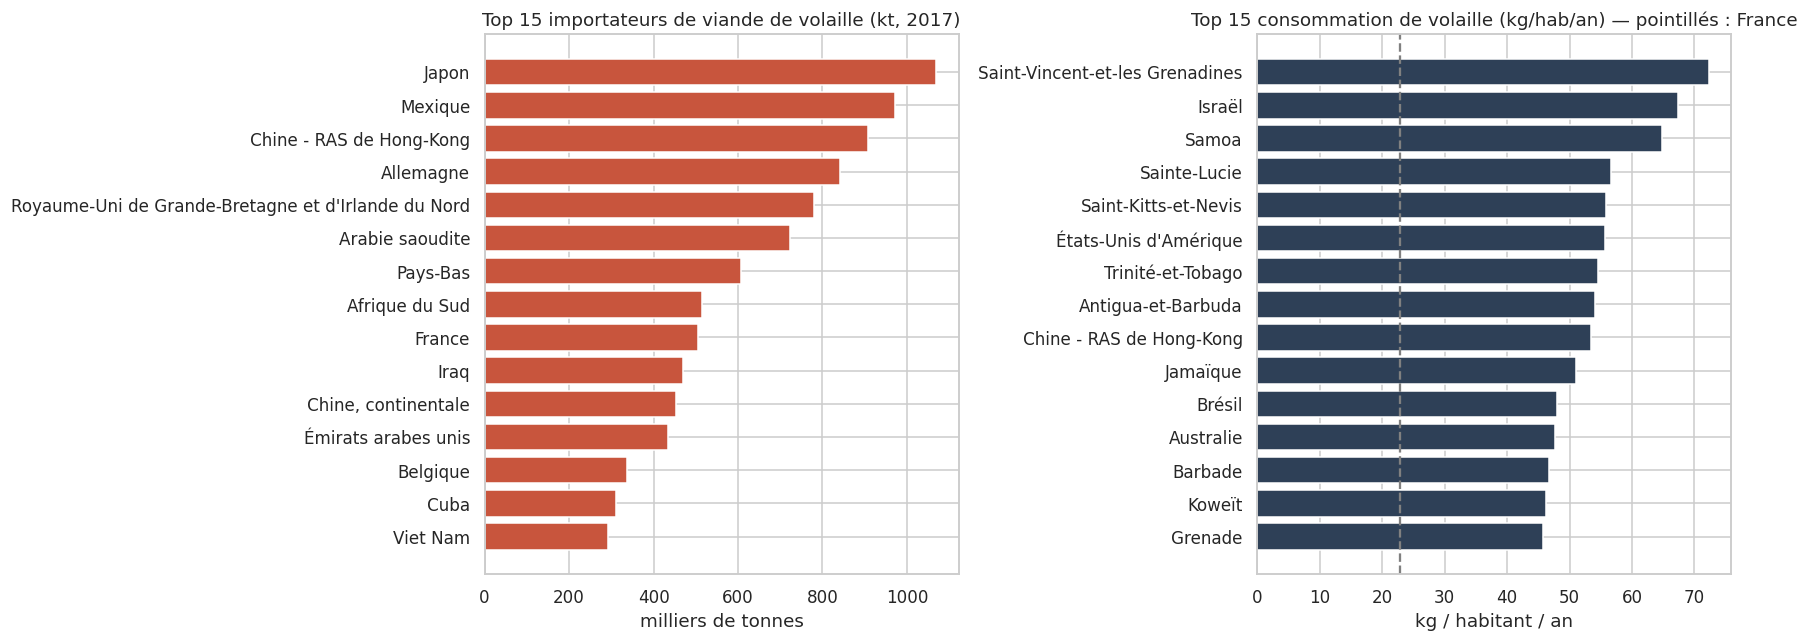

In [32]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))
top_imp = df.nlargest(15, "poultry_imports_kt").sort_values("poultry_imports_kt")
axes[0].barh(top_imp["zone"], top_imp["poultry_imports_kt"], color="#C8553D")
axes[0].set_title("Top 15 importateurs de viande de volaille (kt, 2017)")
axes[0].set_xlabel("milliers de tonnes")

top_cons = df.nlargest(15, "poultry_supply_kg_cap").sort_values("poultry_supply_kg_cap")
axes[1].barh(top_cons["zone"], top_cons["poultry_supply_kg_cap"], color="#2E4057")
axes[1].axvline(df.loc[df["iso3"] == "FRA", "poultry_supply_kg_cap"].iloc[0], ls="--", c="grey")
axes[1].set_title("Top 15 consommation de volaille (kg/hab/an) — pointillés : France")
axes[1].set_xlabel("kg / habitant / an")
plt.tight_layout()
plt.show()

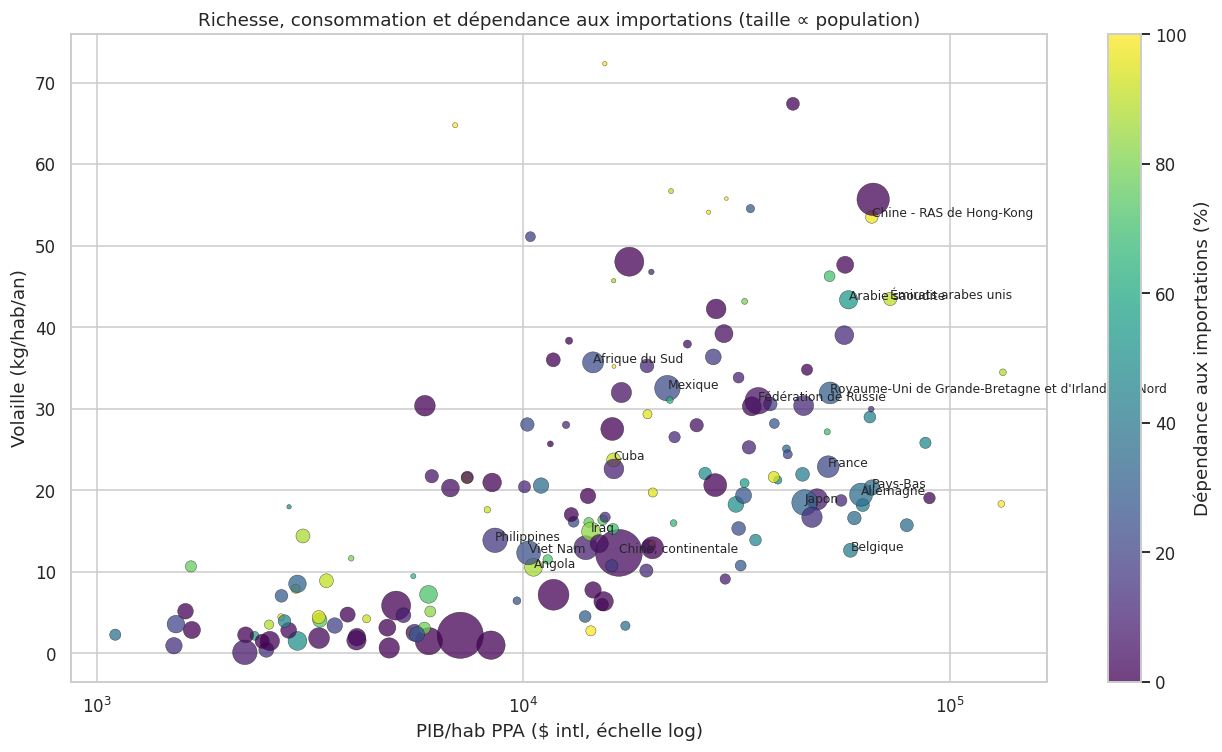

In [33]:
fig, ax = plt.subplots(figsize=(12, 7))
sc = ax.scatter(df["gdp_cap_ppp"], df["poultry_supply_kg_cap"], s=np.sqrt(df["population"]) / 40,
                c=df["import_dependency_pct"], cmap="viridis", alpha=.75, edgecolor="k", lw=.3)
ax.set_xscale("log")
ax.set_xlabel("PIB/hab PPA ($ intl, échelle log)")
ax.set_ylabel("Volaille (kg/hab/an)")
plt.colorbar(sc, label="Dépendance aux importations (%)")
for _, r in df.nlargest(18, "poultry_imports_kt").iterrows():
    ax.annotate(r["zone"], (r["gdp_cap_ppp"], r["poultry_supply_kg_cap"]), fontsize=8)
ax.set_title("Richesse, consommation et dépendance aux importations (taille ∝ population)")
plt.tight_layout()
plt.show()

La consommation de volaille croît avec le revenu, mais à revenu égal les écarts sont forts (culture alimentaire). Les marchés **riches et fortement importateurs** (Royaume-Uni, Pays-Bas, Japon, Arabie saoudite, Émirats, Hong Kong…) ressortent déjà comme des candidats naturels pour un produit premium.

In [34]:
region_view = (df.groupby("wb_region")
                 .agg(n_countries=("zone", "size"),
                      population_m=("population", lambda s: s.sum() / 1e6),
                      imports_kt=("poultry_imports_kt", "sum"),
                      median_kg_cap=("poultry_supply_kg_cap", "median"),
                      median_gdp_cap=("gdp_cap_ppp", "median"))
                 .sort_values("imports_kt", ascending=False).round(0))
region_view

,n_countries,population_m,imports_kt,median_kg_cap,median_gdp_cap
wb_region,,,,,
Europe & Central Asia,47,882.0,5610.0,19.0,35043.0
East Asia & Pacific,21,2277.0,3281.0,17.0,12597.0
"Middle East, North Africa, Afghanistan & Pakistan",18,653.0,2207.0,19.0,14923.0
Latin America & Caribbean,33,631.0,2088.0,34.0,16314.0
Sub-Saharan Africa,40,927.0,1532.0,4.0,3473.0
North America,2,362.0,305.0,47.0,61388.0
South Asia,5,1548.0,12.0,2.0,7116.0


## 10. Couverture et export

In [35]:
world_pop_2017 = pop_raw.loc[(pop_raw["Année"] == REF_YEAR), "Valeur"].sum() * 1000
coverage = df["population"].sum() / world_pop_2017 * 100
print(f"Countries kept: {len(df)}")
print(f"Population covered: {df['population'].sum() / 1e9:.2f} bn / {world_pop_2017 / 1e9:.2f} bn "
      f"= {coverage:.1f} %")
assert len(df) >= 100 and coverage >= 60

Countries kept: 166
Population covered: 7.28 bn / 7.55 bn = 96.5 %


Objectifs du brief atteints : **166 pays** (> 100) couvrant **≈ 96 % de la population mondiale** (> 60 %).

In [36]:
ID_COLS = ["iso3", "zone", "wb_region", "income_group", "capital"]
RAW_KEEP = ["population", "poultry_production_kt", "poultry_imports_kt", "poultry_exports_kt",
            "poultry_domestic_supply_kt", "poultry_food_market_kt", "gdp_cap_ppp", "distance_paris_km"]
final = df[ID_COLS + RAW_KEEP + [c for c in FEATURES if c not in RAW_KEEP]].reset_index(drop=True)
final.to_csv(DATA_DIR / "p11_countries_clean.csv", index=False)
print(final.shape)
final.head()

(166, 25)


,iso3,zone,wb_region,income_group,capital,population,poultry_production_kt,poultry_imports_kt,poultry_exports_kt,poultry_domestic_supply_kt,poultry_food_market_kt,gdp_cap_ppp,distance_paris_km,poultry_supply_kg_cap,log_poultry_imports,import_dependency_pct,poultry_share_meat_pct,animal_protein_share_pct,log_population,pop_growth_10y_pct,log_gdp_cap_ppp,urban_pct,political_stability,regulatory_quality,lpi_score
0,ARM,Arménie,Europe & Central Asia,Upper middle income,Yerevan,2944791.0,11.0,35.0,0.0,47.0,47.293343,14243.874900,3431.470023,16.06,1.556303,76.086957,35.180723,45.782390,6.469054,0.415090,4.153628,64.712495,-0.301588,0.265850,2.61
1,AFG,Afghanistan,"Middle East, North Africa, Afghanistan & Pakistan",Low income,Kabul,36296113.0,28.0,29.0,0.0,57.0,55.533053,2952.998916,5581.827163,1.53,1.477121,50.877193,17.811409,19.523017,7.559860,33.931347,3.470263,24.835282,-2.613931,-1.416448,1.95
2,ALB,Albanie,Europe & Central Asia,Upper middle income,Tirane,2884169.0,13.0,38.0,0.0,47.0,47.185005,15359.397458,1600.454391,16.36,1.591065,74.509804,34.434856,55.497908,6.460021,-4.938335,4.186374,55.980276,0.163830,0.110524,2.66
3,DZA,Algérie,"Middle East, North Africa, Afghanistan & Pakistan",Upper middle income,Algiers,41389189.0,275.0,2.0,0.0,277.0,264.063026,15427.664189,1348.527400,6.38,0.477121,0.722022,35.346260,27.679052,7.616887,21.138007,4.188300,71.322791,-0.929505,-0.945914,2.45
4,AGO,Angola,Sub-Saharan Africa,Lower middle income,Luanda,29816766.0,42.0,277.0,0.0,319.0,314.865049,10565.167648,6500.304191,10.56,2.444045,86.833856,44.974446,30.449251,7.474461,42.627354,4.023876,65.085053,-0.537214,-1.179988,2.05


### Dictionnaire des 13 variables d'analyse
| Variable | Description | Source | Création |
|---|---|---|---|
| `poultry_supply_kg_cap` | Disponibilité alimentaire volaille (kg/hab/an) | FAO | — |
| `log_poultry_imports` | log₁₀(1 + importations volaille en kt) | FAO | transformation |
| `import_dependency_pct` | Importations / (production + importations) | FAO | **feature engineering** |
| `poultry_share_meat_pct` | Part de la volaille dans la viande consommée | FAO | **feature engineering** |
| `animal_protein_share_pct` | Part des protéines animales | FAO | **feature engineering** |
| `log_population` | log₁₀(population 2017) | FAO | transformation |
| `pop_growth_10y_pct` | Croissance de la population 2007-2017 | FAO | **feature engineering** |
| `log_gdp_cap_ppp` | log₁₀(PIB/hab PPA) | Banque mondiale | transformation |
| `urban_pct` | Population urbaine (%) | Banque mondiale | — |
| `political_stability` | Stabilité politique (WGI) | Banque mondiale | — |
| `regulatory_quality` | Qualité de la réglementation (WGI) | Banque mondiale | — |
| `lpi_score` | Logistics Performance Index 2018 | Banque mondiale | — |
| `distance_paris_km` | Distance Paris – capitale (km) | Banque mondiale (coord.) | **feature engineering** |

**Conclusion.** Un fichier unique `p11_countries_clean.csv` rassemble **13 variables** couvrant les 6 axes PESTEL, dont **5 créées par feature engineering**, pour 166 pays. Il alimente le notebook 2 (ACP et clustering).